# Validating against a product

`arrayprobe.compare_to_product` is the acceptance gate for a combined product, in
typed form -- both denominators (both-present
and non-zero), the used-bin convention, and the seconds where a real residual
lives. No campaign data: this builds a demo flight and its own combined
product, then compares that product against itself to show the mechanics --
against a real archived product the two sides would come from different
processing runs, and could disagree.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (Reading the output files). **Next:** [02_known_truth](02_known_truth.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

**Where this sits on the evidence ladder.** Sections 2, 2b and 2c compare the port against
itself or against its own tracked reference output -- a regression check, useful for catching a
change in the port, but not evidence at any layer, since neither side is an archived MATLAB
product or the original source executing. **Section 2d is the exception, and it is layer 1**:
real cut slices of archived products from the validation campaign, and it runs only
where that data is present. Section 3 quotes a layer-1 figure (99.9080%) measured on a real
held-out flight; that flight's data is not distributed with this package, and the
shipped results of record are in `docs/04-validation.md`.

## 1. Build a demo flight's combined product


In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/3_validation/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys
import tempfile
from pathlib import Path

sys.path.insert(0, "scripts")
import make_demo_flight  # noqa: E402
import run_flight  # noqa: E402
from arrayprobe import combine_sizedist, compare_to_product  # noqa: E402

run_flight.log = lambda *a, **kw: None

tmp = tempfile.TemporaryDirectory()
out = Path(tmp.name)
# The public package runs the v3.5 engine: this sets engine, profile and a constant-TAS aircraft file.
run_flight.use_engine_35(out)
raw = out / "base160101000000.2DS"
make_demo_flight.build_demo_flight(raw, n_seconds=5)

image = run_flight.stage2(raw, out)
proc = run_flight.stage3(image, out)
sd = run_flight.stage4(proc, raw.stem, out)

stem = raw.stem
flight_date = f"20{stem[4:10]}"
summary_time = '_'.join(stem[i:i + 2] for i in range(4, 16, 2))
from arrayprobe_uiops.decode_naming import combined_name  # noqa: E402
combined = out / combined_name(stem, "H", "2DS", "3.5")  # v3.5 names it without "_2"
combine_sizedist([str(sd)], str(combined), flight_date=flight_date,
                 summary_time=summary_time)
print(f"combined product: {combined.name}, {combined.stat().st_size:,} bytes")


combined product: base160101000000.combined.H.2DS.cdf, 68,129,052 bytes


**The same files, opened as an `xarray` Dataset.** Earth-science users usually reach for `xarray`; the package itself does not depend on it, but its output files open directly. The next cell shows the `sd` file's structure and plots its size distribution with `.plot`, before the comparison below.


<xarray.Dataset> Size: 172kB
Dimensions:          (Time: 4, CIPcorrlen: 128, CIParealen: 10, Habit: 10)
Dimensions without coordinates: Time, CIPcorrlen, CIParealen, Habit
Data variables: (12/23)
    time             (Time) float64 32B 6.064e+04 6.064e+04 6.064e+04 6.064e+04
    bin_min          (CIPcorrlen) float64 1kB 0.005 0.015 0.025 ... 1.265 1.275
    bin_max          (CIPcorrlen) float64 1kB 0.015 0.025 0.035 ... 1.275 1.285
    bin_mid          (CIPcorrlen) float64 1kB 0.01 0.02 0.03 ... 1.26 1.27 1.28
    bin_dD           (CIPcorrlen) float64 1kB 0.01 0.01 0.01 ... 0.01 0.01 0.01
    conc_minR        (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    ...               ...
    Prec_rate        (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    habitmsd         (Time, CIPcorrlen, Habit) float64 41kB 0.0 0.0 ... 0.0 0.0
    Calcd_area       (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    count            (Time, CIPcorrlen) float64 4kB 0.0 0.

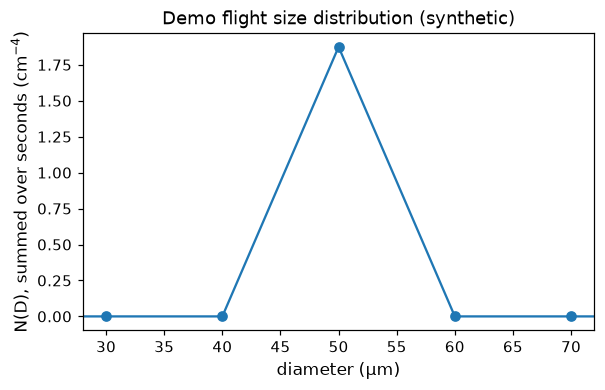

In [2]:
import re


def without_local_paths(data):
    """A copy whose path-valued global attributes keep only the file name.

    The file records the absolute path of the input the demo run read; showing it
    would print a folder on this machine. The file on disk is unchanged."""
    shown = data.copy()
    shown.attrs = {k: re.split(r"[/\\]", v)[-1] if isinstance(v, str) and re.match(r"(~|[A-Za-z]:|/)", v) else v
                   for k, v in data.attrs.items()}
    return shown


import matplotlib.pyplot as plt
import xarray as xr

# Raw stored values, as the file holds them; the package's own reader does the same.
with xr.open_dataset(sd, mask_and_scale=False, decode_times=False) as ds:
    ds = ds.load()
print(without_local_paths(ds))

# Label the bin axis with the bin midpoints, then plot the time-summed concentration.
import numpy as np

psd = ds["conc_minR"].sum("Time")
d_um = ds["bin_mid"].values * 1000.0           # mm -> µm, for the axis only
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(d_um, psd.values, marker="o")
nz = np.flatnonzero(psd.values)
if nz.size:                                    # zoom to the bins that hold particles
    lo, hi = d_um[max(nz[0] - 2, 0)], d_um[min(nz[-1] + 2, d_um.size - 1)]
    ax.set_xlim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
ax.set_xlabel("diameter (µm)")
ax.set_ylabel(r"N(D), summed over seconds (cm$^{-4}$)")
ax.set_title("Demo flight size distribution (synthetic)")
plt.show()


*Figure 1. The demo flight's size distribution, summed over its seconds and read with xarray (synthetic demo data). The axis is zoomed to the bins that hold particles; every other bin is zero.*

## 2. Compare it -- against itself, here

`compare_to_product(ours, theirs)` returns a `ProductComparisonReport`: coverage
(shared seconds, seconds present on only one side), and a `CellAgreement` per
variable and bin scope, with both denominators this project's own headlines
always report side by side -- see `docs/11-glossary.md`.


In [3]:
report = compare_to_product(str(combined), str(combined))

print(f"shared seconds: {report.shared_seconds}")
print(f"uncovered (theirs only): {report.uncovered_ref_seconds}")
print(f"uncovered (ours only):   {report.uncovered_ours_seconds}")
print(f"residual seconds: {report.residual_seconds}")
print()

for scope in ("all bins", "used bins 6-128"):
    cell = report.cell("Counts", scope)
    print(f"Counts, {scope}:")
    print(f"  both-present {cell.both_present_agree}/{cell.both_present_n} "
          f"({cell.both_present_pct:.4f}%)")
    print(f"  non-zero     {cell.non_zero_agree}/{cell.non_zero_n} "
          f"({cell.non_zero_pct:.4f}%)")

# The demo particle is tiny and, under this profile's shattering threshold,
# does not survive into a used-bin count -- the same limit 01_quickstart.ipynb
# states plainly. nan is the honest answer when the non-zero denominator is
# itself zero, not an error.


shared seconds: 22004
uncovered (theirs only): 0
uncovered (ours only):   0
residual seconds: ()

Counts, all bins:
  both-present 512/512 (100.0000%)
  non-zero     4/4 (100.0000%)
Counts, used bins 6-128:
  both-present 492/492 (100.0000%)
  non-zero     0/0 (nan%)


## 2c. The same check for the v3.5 engine -- the default a new user runs

`tests/data/demo_flight_v35_*` is the v3.5 reference: made through the one line a user runs,
`arrayprobe run tests/data/demo_flight_v35_run.toml <raw>`, under the **stock-v3.5** profile --
the configuration a new user should run; nothing in it is campaign-specific -- with the seeded
synthetic aircraft TAS file the tool writes (`make_demo_reference.write_aircraft_v35`). The v3.5
engine writes NETCDF4 files whose only run-to-run differences are the `Creation Time` and
source-path global attributes, so the comparison is by variable and tolerance class, as above;
v3.5's four extra per-particle variables are classified in `compare.PROC_CLASSES_V35`.


In [5]:
import make_demo_reference  # noqa: E402  (scripts/ is on sys.path from cell 1)
from arrayprobe import compare

REF = Path("tests/data")

print(Path("tests/data/demo_flight_v35_run.toml").read_text())
tmp35 = tempfile.TemporaryDirectory()
paths35 = make_demo_reference.build_v35(Path(tmp35.name))
print("ran:", paths35["command"].replace(str(Path(tmp35.name)), "<tmp>"))
print()
for kind, classes in (("proc", compare.PROC_CLASSES_V35), ("sd", None)):
    report = compare.compare_files(str(paths35[kind]), str(REF / f"demo_flight_v35_{kind}.nc"),
                                   classes=classes)
    print(f"== v3.5 {kind}: {report.join.n_matched} joined, accepted={report.accepted()}")
    print(compare.format_report(report))
    assert report.accepted(), compare.describe_differences(report)
problems = make_demo_reference._compare_v35(paths35, REF)
print("whole v3.5 reference (raw, toml, aircraft, image digest, proc, sd, 4 sidecars, combined digest):",
      "ok" if not problems else problems)
assert not problems, problems


# The v3.5 demo-flight reference's run configuration (built by scripts/make_demo_reference.py).
# stock-v3.5 is the configuration a new user should run: nothing here is ORACLES-specific.
# Paths are relative to this file. `arrayprobe run demo_flight_v35_run.toml <raw.2DS>`.
[fidelity]
profile = "stock-v3.5"

[run]
engine = "3.5"
preset = "DEMO_2DS_H"
out = "_decoded"
stages = "234c"
tas_file = "demo_flight_v35_aircraft.cdf"

[combine]
borrowed = true

ran: python -m arrayprobe.cli run <tmp>\demo_flight_v35_run.toml <tmp>\base160101000000.2DS

== v3.5 proc: 5 joined, accepted=True
left : <tmp>\_decoded\proc.base160101000000.H.nc
right: tests\data\demo_flight_v35_proc.nc

JOIN  Date | Time | parent_rec_num | position
  matched 5 of 5 left / 5 right (100.0000%)

VARIABLE                           CLS  VERDICT     N DIFF  DETAIL

42/42 variables bit-exact over the joined particles.
ACCEPTED: True
== v3.5 sd: 4 joined, accepted=True
left : <tmp>\_decoded\sd.base160101000000.H.nc
right: test

## 2d. Validate against a real second-window from the validation campaign (2016-09-10 and 2017-08-24)

Two small, byte-exact record slices of real flights from the validation campaign -- one 2016, one 2017 -- each
paired with a matching cut of its archived product. The window on each flight
is chosen to maximise used-bin particle
count subject to a byte cap.

**Why the comparison excludes the outermost second on each side.** The cut adds one second of
margin before and after the reported window, plus one extra trailing raw record, so the first
particle *inside* the window always has a real predecessor for its inter-arrival time -- the
comparison below reports only the *interior* seconds and explains why in the printed output.

**This section needs data you supply.** It shows a run compared second by second with an archived
product on real flights. The raw slices and cut products are not distributed; only their manifests
are. The cell below runs only when you have an archived product of your own, with its raw data, in
the folder it reads; otherwise it prints the command that regenerates the cut and moves on, so the
notebook runs cleanly either way.

**What this section costs, where the gate is open.** Minutes, not seconds: the cell below
decodes two real raw slices through the whole stage-2/3/4 chain. Measured on one
workstation 2026-09-17: **900 s** for this section, **908 s
(15 min)** for the notebook end to end. Cell 1 stubs `run_flight.log` silent,
so the cell announces itself and prints each year as it lands rather than leaving the
screen blank for a quarter of an hour -- a silent run measured 2026-09-16 took
1508 s and then a later cell raised
(recorded in the development dry run of this demonstration).
**The saved output below is the answer: read it rather than re-running it.** Where the
subsets are absent -- every fresh clone -- the cell prints the regenerate command instead
and the whole notebook finishes in seconds.


In [6]:
import time
from pathlib import Path

subset_dir = Path("tests/data/oracles_subsets")
if not list(subset_dir.glob("*.2DS")):
    print("The validation-campaign subset gate is closed on this machine: no *.2DS files under", subset_dir)
    print("Nothing below needs them, and this takes under a second: the saved output of")
    print("this notebook already shows what the open gate produces.")
    print("This section needs an archived product of your own: put record slices of its raw")
    print("files, with the matching cut of the product, under that directory.")
else:
    import json
    import tempfile

    import make_demo_reference  # noqa: E402  (scripts/ is on sys.path from cell 1)

    # THE ONE EXPENSIVE CELL IN THIS NOTEBOOK. Each year decodes a real ~4 MB raw
    # slice through the whole stage-2/3/4 chain and compares it against the cut archived
    # product -- minutes, not seconds, and cell 1 stubs run_flight.log silent, so without
    # the lines below the screen stays blank throughout. Read the saved output instead of
    # re-running this: it is the same answer.
    n_subsets = len(list(subset_dir.glob("*.2DS")))
    print(f"The validation-campaign subset is present on this machine: {n_subsets} raw subset(s) under {subset_dir}.")
    print("Decoding 2016 and 2017 for real. Minutes, not seconds; each year prints as it lands.")

    results = {}
    started = time.monotonic()
    for year in (2016, 2017):
        year_started = time.monotonic()
        with tempfile.TemporaryDirectory() as year_tmp:
            results[year] = make_demo_reference.check_oracles_subset(year, Path(year_tmp))
        print(f"  {year} decoded and compared in {time.monotonic() - year_started:.0f} s")
    print(f"both years in {time.monotonic() - started:.0f} s\n")

    for year, result in results.items():
        t0, t1 = result["interior_seconds"]
        print(f"{year}: interior seconds [{t0}, {t1}], "
              f"Counts agreement {result['counts_non_zero_pct']:.4f}%, "
              f"Size Distribution agreement {result['sd_non_zero_pct']:.4f}%, "
              f"residual seconds {result['interior_residual_seconds']}")


The validation-campaign subset gate is closed on this machine: no *.2DS files under tests\data\oracles_subsets
Nothing below needs them, and this takes under a second: the saved output of
this notebook already shows what the open gate produces.
This section needs an archived product of your own: put record slices of its raw
files, with the matching cut of the product, under that directory.


Plot the agreement for each year as a bar, and below it the archived particle counts per second for the 2016 window, so you can see how dense the sample is. If the gate above is closed on this machine, the cell prints a one-line message and skips the plot.

In [7]:
if list(subset_dir.glob("*.2DS")):
    import netCDF4
    import numpy as np
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    years = list(results.keys())
    pct = [results[y]["counts_non_zero_pct"] for y in years]
    axes[0].bar([str(y) for y in years], pct)
    axes[0].set_ylim(0, 100)
    axes[0].set_ylabel("used-bin Counts agreement (%)")
    axes[0].set_title("Validation-campaign subsets: interior-second agreement")

    # Interior-second used-bin Counts, archive only (both engines agree where accepted() above
    # holds, so a single line establishes the shape; a fresh run and the archive would overplot).
    manifest_2016 = json.loads(
        (subset_dir / "oracles_2016_manifest.json").read_text())
    with netCDF4.Dataset(str(subset_dir / manifest_2016["product_subset_name"])) as ds:
        tv = np.asarray(ds.variables["Time Vector"][:], float)
        sod = np.round((tv - np.floor(tv[0])) * 86400.0).astype(np.int64)
        counts = np.asarray(ds.variables["Counts"][:], float)
        if counts.ndim == 2 and counts.shape[1] != len(sod):
            counts = counts.T
        used = np.nansum(counts[5:], axis=0)
    t0, t1 = results[2016]["interior_seconds"]
    interior = (sod >= t0) & (sod <= t1)
    axes[1].plot(sod[interior], used[interior], marker="o", label="2016-09-10 (archive)")
    axes[1].set_xlabel("second of day (interior window)")
    axes[1].set_ylabel("used-bin Counts, summed over bins")
    axes[1].set_title("2016 interior-second density")
    axes[1].legend(fontsize=8)

    fig.tight_layout()
else:
    print("The validation-campaign subset gate is closed on this machine: the subset plot is skipped (see the cell above).")


The validation-campaign subset gate is closed on this machine: the subset plot is skipped (see the cell above).


## 2e. One second, bin by bin

When a validation finds a differing second, the next question is *which bins, and which
particles*. `arrayprobe.diagnostic_views.compare_second` sets one second of two `sd` files side by
side and lists the proc rows of that second whose diameter falls in a differing bin, with their
reject codes -- where to look, not what was counted, since `count` also requires the codes,
centre-in and time window to pass. Against the tracked reference this run agrees everywhere; the
same call on a copy with one cell changed names exactly that cell and its particle.


In [8]:
import shutil
import warnings

import netCDF4
from arrayprobe.diagnostic_views import compare_second

sd35, proc35 = paths35["sd"], paths35["proc"]
print(compare_second(sd35, REF / "demo_flight_v35_sd.nc", 60640, proc=proc35).summary())

changed = out / "sd_one_cell_changed.nc"
shutil.copyfile(sd35, changed)
# netCDF4 1.7 under numpy 2.5 warns about its own internal reshape here; nothing is wrong.
with netCDF4.Dataset(str(changed), "a") as ds, warnings.catch_warnings():
    warnings.simplefilter("ignore", DeprecationWarning)
    ds.variables["count"][0:1, 4:5] = [[3.0]]   # second 060640, bin 5
print(compare_second(sd35, changed, 60640, proc=proc35).summary())


second 060640, variable 'count': 0 of 128 bin(s) differ (exact)
  0 particle(s) of this second fall in a differing bin by image_diam_minR
second 060640, variable 'count': 1 of 128 bin(s) differ (exact)
  bin   5 [0.045, 0.055): ours 1  theirs 3  diff -2
  1 particle(s) of this second fall in a differing bin by image_diam_minR
    proc row 0: bin 5, image_diam_minR 0.04801, reject h, centre-in 1


## 3. What a real residual looks like

Comparing a file against itself always agrees -- that is what confirms the
mechanics work, not what a validation finds in practice. On a real held-out
flight from the validation campaign (2016-09-20; not distributed with this package), this same
comparison reports **99.9080%** agreement on non-zero used-bin cells
(13,027 / 13,039) -- twelve differing cells, all in a *single* residual
second, where the archived product's neighbouring second is entirely fill
while the port holds particles there. `report.residual_seconds` for that
flight would be a tuple with exactly that one second in it.


---

## Validate your own run

Point this at two files and get the same comparison
the first half of this notebook demonstrates on tracked demo data:
your own combined product against the archived product ("already run by
MATLAB"), or against a second run of this port, or against your own MATLAB
output ("run by them anew") -- `compare_to_product` takes two arbitrary
files, not one committed pair.

**Edit only the next cell.** Every cell after it reads from those two
variables, never from a hard-coded name.

In [9]:
if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/), so run "
        "`%cd ..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

from pathlib import Path

OURS = None       # e.g. Path("../_decoded/base160906064403.combined.H.2DS.cdf")
REFERENCE = None  # e.g. Path("/path/to/your/product_folder/
                   #      base160906064017.combined.H.2DS_2.cdf")


## No files given: fall back to a demo pair

This keeps the notebook runnable end to end with no campaign data (the same
reason every notebook under `examples/` is), so it stays checked by
`test_examples_execute.py`. If you set `OURS`/`REFERENCE` above, this cell
does nothing -- it only fills the gap when they are still `None`.


In [10]:
if OURS is None or REFERENCE is None:
    import sys
    import tempfile

    sys.path.insert(0, "scripts")
    import make_demo_flight  # noqa: E402
    import run_flight  # noqa: E402
    from arrayprobe import combine_sizedist  # noqa: E402

    run_flight.log = lambda *a, **kw: None
    demo_tmp = tempfile.TemporaryDirectory()
    demo_out = Path(demo_tmp.name)
    run_flight.use_engine_35(demo_out)  # v3.5 engine, stock-v3.5 profile, constant-TAS aircraft file
    raw = demo_out / "base160101000000.2DS"
    make_demo_flight.build_demo_flight(raw, n_seconds=5)
    image = run_flight.stage2(raw, demo_out)
    proc = run_flight.stage3(image, demo_out)
    sd = run_flight.stage4(proc, raw.stem, demo_out)

    stem = raw.stem
    from arrayprobe_uiops.decode_naming import combined_name  # noqa: E402
    combined = demo_out / combined_name(stem, "H", "2DS", "3.5")
    combine_sizedist([str(sd)], str(combined), flight_date=f"20{stem[4:10]}",
                     summary_time='_'.join(stem[i:i + 2] for i in range(4, 16, 2)))
    OURS, REFERENCE = combined, combined
    print(f"no files given -- using a demo pair: {combined.name} against itself")


no files given -- using a demo pair: base160101000000.combined.H.2DS.cdf against itself


The same file in xarray, which most earth-science tools read:

<xarray.Dataset> Size: 68MB
Dimensions:                    (time: 22004, bin_count: 128)
Dimensions without coordinates: time, bin_count
Data variables:
    Time Vector                (time) float64 176kB 7.363e+05 ... 7.363e+05
    Bin Minimum                (bin_count) float64 1kB 0.005 0.015 ... 1.275
    Bin Maximum                (bin_count) float64 1kB 0.015 0.025 ... 1.285
    Bin Midpoints              (bin_count) float64 1kB 0.01 0.02 ... 1.27 1.28
    Bin Width                  (bin_count) float64 1kB 0.01 0.01 ... 0.01 0.01
    Mean Area Ratio            (bin_count, time) float64 23MB nan nan ... nan
    Counts                     (bin_count, time) float64 23MB nan nan ... 0.0
    Size Distribution cm-3     (bin_count, time) float64 23MB nan nan ... 0.0
    Number Concentration cm-3  (time) float64 176kB nan nan ... 0.0004686
    Reject Ratio               (time) float64 176kB nan nan nan ... 0.0 0.0 0.0


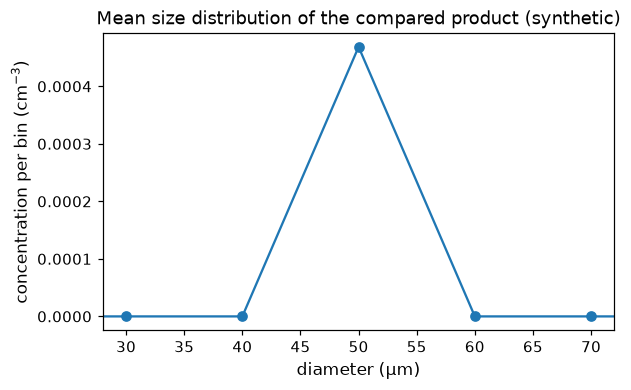

In [11]:
import matplotlib.pyplot as plt
import xarray as xr

with xr.open_dataset(OURS) as ds:
    ds = ds.load()
print(ds)
import numpy as np

mean_psd = ds["Size Distribution cm-3"].mean("time").values
d_um = ds["Bin Midpoints"].values * 1000.0      # mm -> µm, for the axis only
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(d_um, mean_psd, marker="o")
nz = np.flatnonzero(np.nan_to_num(mean_psd))
if nz.size:                                     # zoom to the bins that hold particles
    lo, hi = d_um[max(nz[0] - 2, 0)], d_um[min(nz[-1] + 2, d_um.size - 1)]
    ax.set_xlim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
ax.set_xlabel("diameter (µm)")
ax.set_ylabel(r"concentration per bin (cm$^{-3}$)")
ax.set_title("Mean size distribution of the compared product (synthetic)")
plt.show()

*Figure 2. The time-mean size distribution of the product being compared, read with xarray (synthetic demo data). The axis is zoomed to the bins that hold particles.*

## Compare


In [12]:
from arrayprobe import compare_to_product

report = compare_to_product(str(OURS), str(REFERENCE))

print(f"ours:   {Path(OURS).name}")
print(f"theirs: {Path(REFERENCE).name}")
print(f"shared seconds: {report.shared_seconds}  "
      f"(uncovered: {report.uncovered_ours_seconds} ours-only, "
      f"{report.uncovered_ref_seconds} theirs-only)")
print()

for variable in ("Counts", "Size Distribution cm-3"):
    for scope in ("all bins", "used bins 6-128"):
        try:
            cell = report.cell(variable, scope)
        except KeyError:
            continue
        print(f"{variable}, {scope}:")
        print(f"  both-present {cell.both_present_agree}/{cell.both_present_n} "
              f"({cell.both_present_pct:.4f}%)")
        print(f"  non-zero     {cell.non_zero_agree}/{cell.non_zero_n} "
              f"({cell.non_zero_pct:.4f}%)")

print(f"\nresidual seconds: {report.residual_seconds}")


ours:   base160101000000.combined.H.2DS.cdf
theirs: base160101000000.combined.H.2DS.cdf
shared seconds: 22004  (uncovered: 0 ours-only, 0 theirs-only)

Counts, all bins:
  both-present 512/512 (100.0000%)
  non-zero     4/4 (100.0000%)
Counts, used bins 6-128:
  both-present 492/492 (100.0000%)
  non-zero     0/0 (nan%)
Size Distribution cm-3, all bins:
  both-present 512/512 (100.0000%)
  non-zero     4/4 (100.0000%)
Size Distribution cm-3, used bins 6-128:
  both-present 492/492 (100.0000%)
  non-zero     0/0 (nan%)

residual seconds: ()


## Plot the residuals over time

Empty when every non-zero used-bin cell agrees -- the common case once a
configuration is settled (see `docs/04-validation.md`'s per-flight
table for what a real residual pattern looks like across many flights).


In [13]:
import matplotlib.pyplot as plt

if len(report.residual_seconds) == 0:
    # Nothing to draw: say so in words rather than showing an empty axis.
    print(f"All residuals zero: every one of the {report.shared_seconds} shared seconds agrees, "
          "so there is no residual second to plot.")
else:
    fig, ax = plt.subplots(figsize=(7, 2.5))
    ax.eventplot([report.residual_seconds], lineoffsets=0, linelengths=0.8)
    ax.set_xlabel("time (second of day)")
    ax.set_yticks([])
    ax.set_title(f"{len(report.residual_seconds)} second(s) where the two products differ")
    plt.show()


All residuals zero: every one of the 22004 shared seconds agrees, so there is no residual second to plot.


*Figure 3. Seconds where the two products differ, one tick per second; when every shared second agrees, the cell prints that sentence instead of an empty plot.*

## Where to go next

- [Validate your own run](#validate-your-own-run), below -- the same module, pointed at two files
  you supply: your own run and a reference you hold.
- `docs/04-validation.md` -- every held flight's real numbers.
